#Imports

In [30]:
import pandas as pd

#Train Data

In [31]:
# Load the training data (in Colab, upload data/train.zip first)
df_train=pd.read_csv('data/train.zip')

#Test Data

In [32]:
# Load the test data (in Colab, upload data/test.zip first)
df_test=pd.read_csv('data/test.zip')

#Libraries

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re #For regular expressions

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

from sklearn.model_selection import train_test_split, GridSearchCV  #GridSearchCV for ML models, automatically finds the best hyperparameters
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Embedding, LSTM, GRU, SimpleRNN, Bidirectional
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau  #ReduceLROnPlateau helps in adaptive learning rate which improves neural network training, preventing getting stuck in local minima
from tensorflow.keras.layers import Flatten, BatchNormalization

!pip install gensim
from gensim.models import Word2Vec


In [34]:
nltk.download('all')


[nltk_data] Downloading collection 'all'
[nltk_data]    | 
[nltk_data]    | Downloading package abc to /root/nltk_data...
[nltk_data]    |   Package abc is already up-to-date!
[nltk_data]    | Downloading package alpino to /root/nltk_data...
[nltk_data]    |   Package alpino is already up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger is already up-
[nltk_data]    |       to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_eng to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger_eng is already
[nltk_data]    |       up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_ru to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger_ru is already
[nltk_data]    |       up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_r

True

In [35]:
np.random.seed(42)
tf.random.set_seed(42)

#EDA

In [36]:
df_train.shape

(93333, 2)

In [37]:
df_test.shape

(59999, 2)

In [38]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93333 entries, 0 to 93332
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   QA Text  93333 non-null  object
 1   Class    93333 non-null  object
dtypes: object(2)
memory usage: 1.4+ MB


In [39]:
print(f"Columns: {df_test.columns.tolist()}")

Columns: ['QA Text', 'Class']


In [40]:
print(f"Missing values in train set : {df_train.isnull().sum()}")

Missing values in train set : QA Text    0
Class      0
dtype: int64


In [41]:
print(f"Missing values in test set : {df_test.isnull().sum()}")

Missing values in test set : QA Text    0
Class      0
dtype: int64


In [42]:
df_train.head(10)

,QA Text,Class
0,"<html> Question Title:\n <br> What does ""el ch...",Society & Culture
1,<html> Question Title:\n <br> should inlaws be...,Family & Relationships
2,<html> Question Title:\n <br> Personals on my ...,Business & Finance
3,<html> Question Title:\n <br> How many African...,Politics & Government
4,<html> Question Title:\n <br> if you get burne...,Health
5,<html> Question Title:\n <br> Can you trace un...,Business & Finance
6,<html> Question Title:\n <br> my boyfriend loo...,Family & Relationships
7,<html> Question Title:\n <br> why does my spea...,Computers & Internet
8,"<html> Question Title:\n <br> If you have to, ...",Business & Finance
9,<html> Question Title:\n <br> More entertainin...,Entertainment & Music


In [43]:
df_test.head(10)

,QA Text,Class
0,<html>\nQuestion Title:<br>Why does Zebras hav...,Science & Mathematics
1,<html>\nQuestion Title:<br>What did the itsy b...,Education & Reference
2,<html>\nQuestion Title:<br>What is the differe...,Education & Reference
3,<form>\nQuestion Title:<br>Why do women get PM...,Health
4,<html>\nQuestion Title:<br>If your co-worker i...,Health
5,<form>\nQuestion Title:<br>what is the best po...,Computers & Internet
6,<form>\nQuestion Title:<br>What are the risks ...,Health
7,<html>\nQuestion Title:<br>What sea creature s...,Education & Reference
8,<html>\nQuestion Title:<br>What was the first ...,Entertainment & Music
9,<form>\nQuestion Title:<br>Do animals have a s...,Science & Mathematics


In [44]:
count_class=df_train['Class'].value_counts()
print(count_class)

Class
Sports                    9419
Science & Mathematics     9365
Business & Finance        9356
Entertainment & Music     9341
Family & Relationships    9321
Education & Reference     9318
Computers & Internet      9317
Society & Culture         9308
Politics & Government     9298
Health                    9290
Name: count, dtype: int64


In [45]:
print(f"Number of classes: {df_train['Class'].nunique()}")

Number of classes: 10


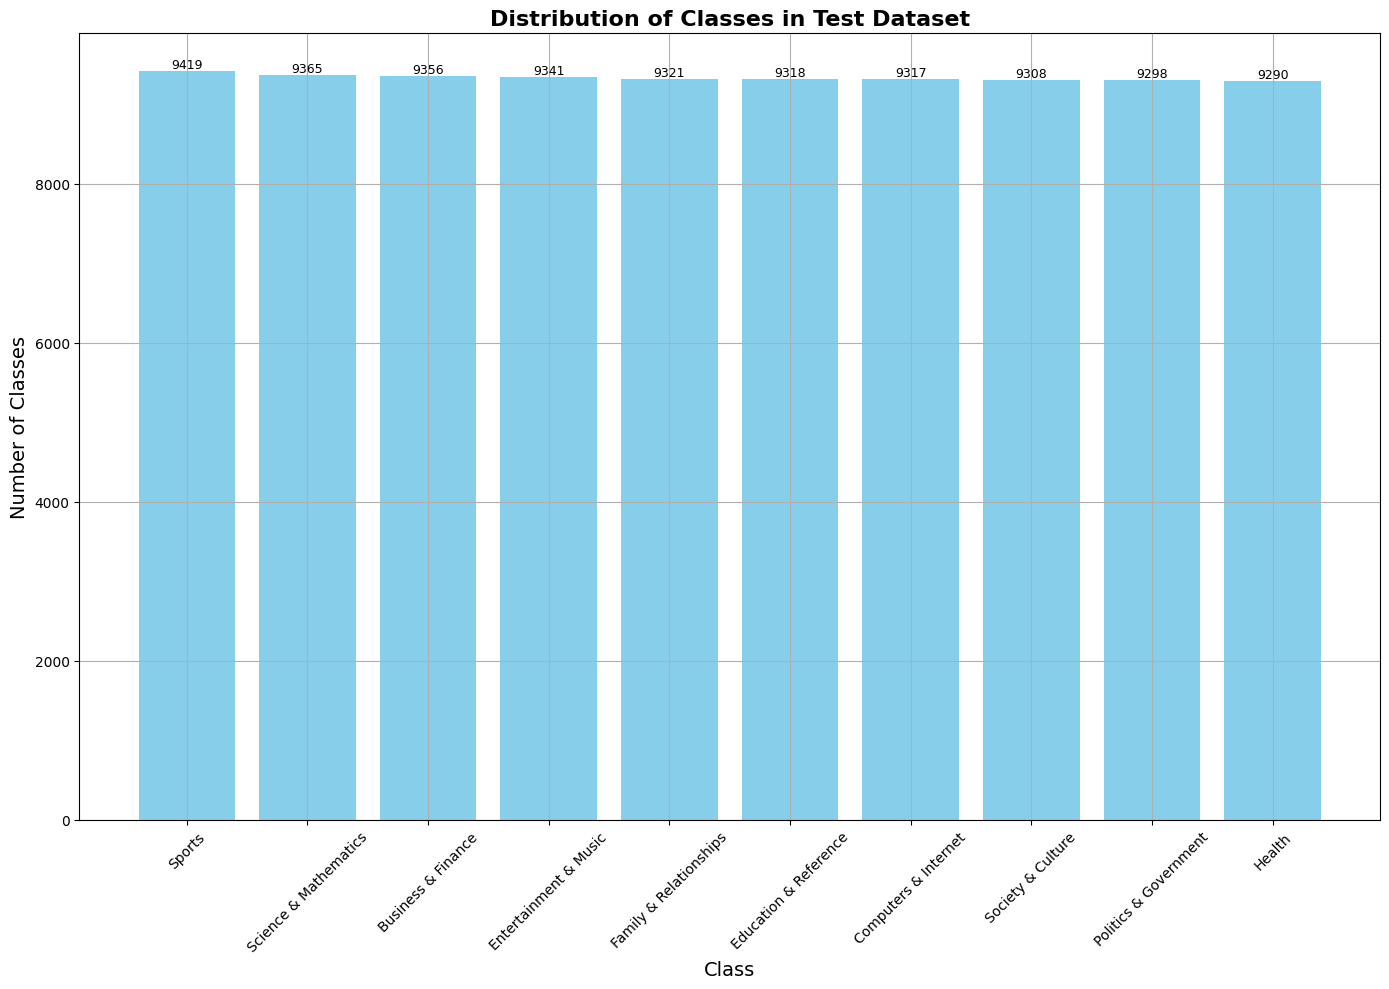

In [46]:
#Class Distribution
plt.figure(figsize=(14,10))
bars=plt.bar(count_class.index,count_class.values,color='skyblue')
plt.title('Distribution of Classes in Test Dataset',fontsize=16,fontweight='bold')
plt.xlabel('Class',fontsize=14)
plt.ylabel('Number of Classes',fontsize=14)
plt.xticks(rotation=45,fontsize=10)
plt.grid()
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x()+bar.get_width()/2,height + 0.5,f'{int(height)}',ha='center',va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

In [47]:
#Removing html text for further analysis
def remove_html_tags(text_html):
    if pd.isna(text_html):
        return ""
    text=str(text_html)
    text = re.sub(r"<.*?>", " ",text)  #remove anything between <>, . indicates a single char, * repeat many times, ? match < as few chars as possible until first . is found
    text = re.sub(r"\s+"," ",text)  #remove additional spaces
    return text.strip()  #remove leading and ending spaces
df_train["clean_text"] = df_train["QA Text"].apply(remove_html_tags)
df_test["clean_text"] = df_test["QA Text"].apply(remove_html_tags)

In [48]:
df_train["clean_text"].head(1)

,clean_text
0,"Question Title: What does ""el chocolate es lo ..."


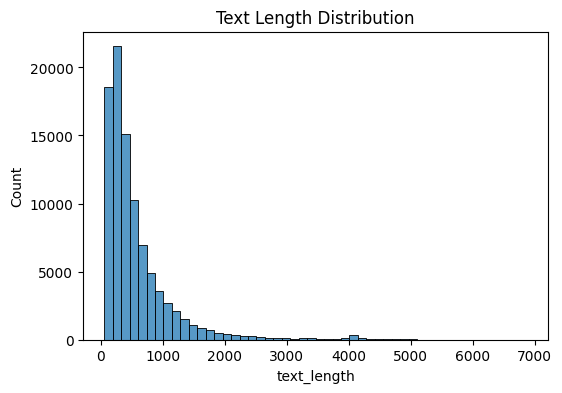

In [49]:
df_train['text_length']= df_train['clean_text'].apply(len)
df_test['text_length']= df_test['clean_text'].apply(len)
plt.figure(figsize=(6,4))
sns.histplot(df_train['text_length'], bins=50)
plt.title("Text Length Distribution")
plt.show()

In [50]:
print(f"Average word count: {df_test['text_length'].mean()}")
print(f"Minimum word count: {df_train['text_length'].min()}")
print(f"Maximum word count: {df_train['text_length'].max()}")

Average word count: 566.288638143969
Minimum word count: 58
Maximum word count: 6877


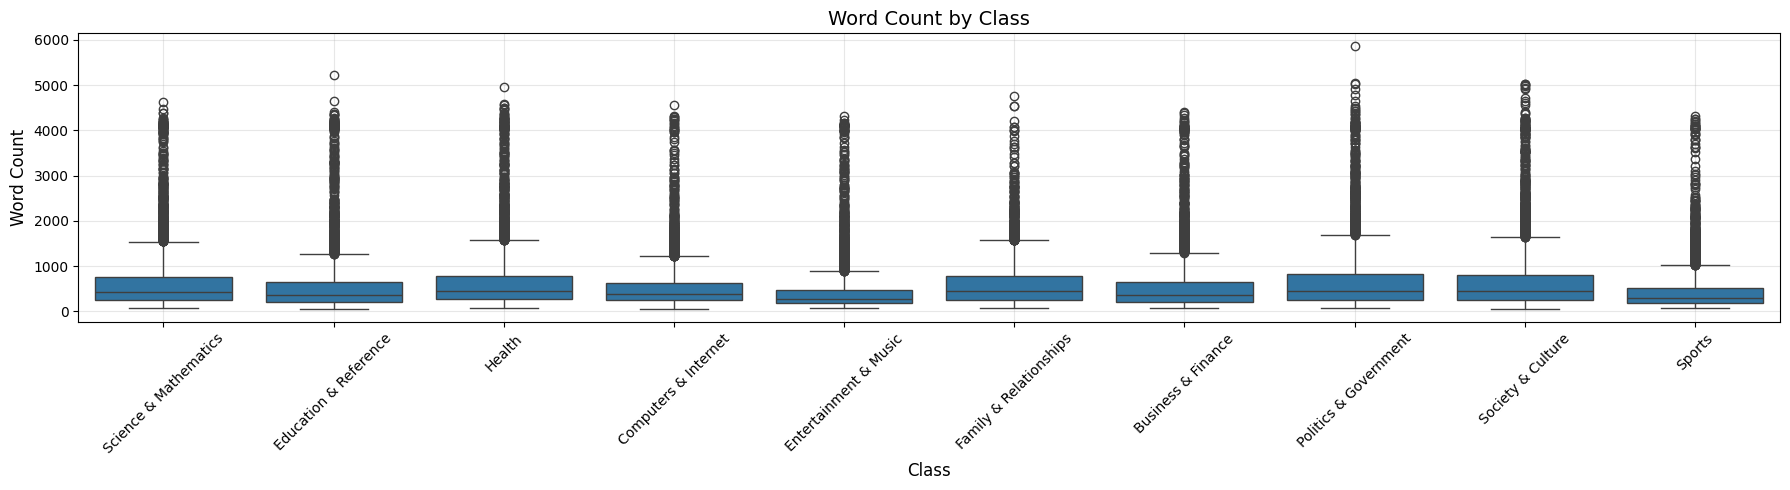

In [51]:
# Box plot by class
fig, axes = plt.subplots(1, 1, figsize=(18, 5))
sns.boxplot(x='Class', y='text_length', data=df_test, ax=axes)
axes.set_title('Word Count by Class', fontsize=14)
axes.set_xlabel('Class', fontsize=12)
axes.set_ylabel('Word Count', fontsize=12)
axes.tick_params(axis='x', rotation=45)
axes.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#Text Preprocessing

In [52]:
stop_words=set(stopwords.words('english'))    #set to remove dups
stemmer=PorterStemmer()
lemmatizer=WordNetLemmatizer()

In [53]:
#Stemming+stopword removal
def stem_preprocess(text):
    if pd.isna(text):
        return ""
    text=str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]',' ',text)   #keep only words, remove special chars
    tokens=word_tokenize(text)
    clean_tokens=[]
    for word in tokens:
        if word not in stop_words:
            clean_tokens.append(word)
    tokens=clean_tokens
    stemmed_tokens=[]
    for word in tokens:
        stemmed_word=stemmer.stem(word)
        stemmed_tokens.append(stemmed_word)
    tokens=stemmed_tokens
    text=' '.join(tokens)        #join the words
    text=re.sub(r'\s+', ' ', text).strip()
    return text

In [54]:
#Stemming+stopword removal
def lemmatize_preprocess(text):
    if pd.isna(text):
        return ""
    text=str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]',' ',text)   #keep only words, remove special chars
    tokens=word_tokenize(text)
    clean_tokens=[]
    for word in tokens:
        if word not in stop_words:
            clean_tokens.append(word)
    tokens=clean_tokens
    lemmatized_tokens=[]
    for word in tokens:
        lemmatized_word=lemmatizer.lemmatize(word)
        lemmatized_tokens.append(lemmatized_word)
    tokens=lemmatized_tokens
    text=' '.join(tokens)        #join the words
    text=re.sub(r'\s+', ' ', text).strip()
    return text

In [55]:
#apply preprocessing to the clean_text(html tags removed)
df_train['stemmed_text']=df_train['clean_text'].apply(stem_preprocess)
df_test['stemmed_text']=df_test['clean_text'].apply(stem_preprocess)
df_train['lemmatized_text']=df_train['clean_text'].apply(lemmatize_preprocess)
df_test['lemmatized_text']=df_test['clean_text'].apply(lemmatize_preprocess)

In [56]:
df_train['stemmed_text'].head(1)

,stemmed_text
0,question titl el chocol es lo ma rico pero tu ...


In [57]:
df_train['lemmatized_text'].head(1)

,lemmatized_text
0,question title el chocolate e lo ma rico pero ...


In [58]:
#encode labels
label_encoder=LabelEncoder()    #assign labels instead of vectors (not one hot encoding)
df_train['encoded_class']=label_encoder.fit_transform(df_train["Class"])
df_test['encoded_class']=label_encoder.transform(df_test["Class"])

In [59]:
df_test['encoded_class'].head(3)

,encoded_class
0,7
1,2
2,2


In [60]:
x_train_stemmed=df_train['stemmed_text'].values
x_test_stemmed=df_test['stemmed_text'].values  #.values convert pd dataframe to numpy array
x_train_lemma=df_train['lemmatized_text'].values
x_test_lemma=df_test['lemmatized_text'].values
y_train=df_train['encoded_class'].values
y_test=df_test['encoded_class'].values

In [61]:
#tfidf on stemmed data
tfidf_vectorizer=TfidfVectorizer(
    max_features=5000,
    ngram_range=(1,2),
    min_df=2,          #ifnore terms appearing in less than 2 docs
    max_df=0.85        #ignore terms appearing in more than 85% of documents
)
x_train_tfidf=tfidf_vectorizer.fit_transform(x_train_stemmed)
x_test_tfidf=tfidf_vectorizer.transform(x_test_stemmed)
x_train_tfidf.shape

(93333, 5000)

In [62]:
feature_names = tfidf_vectorizer.get_feature_names_out()
print(f"Sample features: {feature_names[:20]}")

Sample features: ['ab' 'abandon' 'abc' 'abil' 'abl' 'abl find' 'abl get' 'abnorm' 'abort'
 'abraham' 'abroad' 'absolut' 'absorb' 'abt' 'abus' 'ac' 'academ'
 'academi' 'acceler' 'accent']


In [63]:
def token_for_word2vec(text):    #tokenize the texts
    tokenized_text=[]
    for t in text:
        tokens=word_tokenize(str(t).lower())
        clean_tokens=[]
        for token in tokens:
            if token.isalpha():
                if len(token)>1:
                    clean_tokens.append(token)
        tokenized_text.append(clean_tokens)
    return tokenized_text
tokenized_train=token_for_word2vec(x_train_lemma)
tokenized_test=token_for_word2vec(x_test_lemma)


In [64]:
#Train skipgram model
skipgram_model=Word2Vec(
    sentences=tokenized_train,
    vector_size=100,    #each word size
    window=5,           #4 words to left and right
    min_count=1,        #ignore words with freq less than 1
    sg=1,      #1 for skipgram
    workers=4,        #no. of cpu cores
    epochs=10,
    seed=42
)
print(len(skipgram_model.wv))

148613


In [65]:
max_sequence_length=200 #max word in each row of data)
vocab_size=5000  #total vocab size in whole doc , 5000 most freq words
tokenizer=Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(x_train_lemma)
x_train_seq = tokenizer.texts_to_sequences(x_train_lemma)
x_test_seq = tokenizer.texts_to_sequences(x_test_lemma)

In [66]:
x_train_pad=pad_sequences(x_train_seq,maxlen=max_sequence_length, padding='post', truncating='post')
x_test_pad = pad_sequences(x_test_seq, maxlen=max_sequence_length, padding='post', truncating='post')

In [67]:
x_train_pad.shape

(93333, 200)

In [68]:
def create_embedding_matrix(word_index, embedding_model, embedding_dim):
    vocab_size = len(word_index) + 1  # +1 for padding token
    embedding_matrix = np.zeros((vocab_size, embedding_dim))
    for word, idx in word_index.items():
        if idx < vocab_size:
            if word in embedding_model.wv:
                embedding_matrix[idx] = embedding_model.wv[word]
            else:
                embedding_matrix[idx] = np.random.normal(size=(embedding_dim,))
    return embedding_matrix
word_index = tokenizer.word_index
embedding_matrix = create_embedding_matrix(word_index, skipgram_model, 100)
print(f"Embedding matrix shape: {embedding_matrix.shape}")
print(f"Number of words in vocabulary: {len(word_index)}")

Embedding matrix shape: (148639, 100)
Number of words in vocabulary: 148638


#MODEL TRAINING

In [69]:
all_results=[]

#DNN with tfidf

In [70]:
#dnn
import tensorflow as tf
from tensorflow import keras

# Check GPU availability
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f" GPU Available: {gpus}")
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print("No GPU found, using CPU")

def build_dnn_tfidf(input_dim, num_classes, dropout_rate=0.3):
    """
    Build a Deep Neural Network for TF-IDF features - GPU Optimized
    """
    # Clear previous session
    keras.backend.clear_session()

    # Use GPU if available
    with tf.device('/GPU:0' if gpus else '/CPU:0'):
        model = Sequential([
            Dense(128, activation='relu', input_shape=(input_dim,)),
            Dropout(dropout_rate),
            Dense(64, activation='relu'),
            Dropout(dropout_rate),
            Dense(32, activation='relu'),
            Dropout(dropout_rate),
            Dense(num_classes, activation='softmax')
        ])

        model.compile(
            optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )

    return model

def hyperparameter_tuning_dnn_tfidf(X_train, y_train, X_val, y_val, input_dim, num_classes):

    best_model = None
    best_val_acc = 0
    best_params = {}
    best_history = None

    # Define parameter combinations to test
    param_combinations = [
        {'batch_size': 256, 'epochs': 20, 'dropout': 0.2, 'learning_rate': 0.001},
        {'batch_size': 256, 'epochs': 20, 'dropout': 0.4, 'learning_rate': 0.001},
        {'batch_size': 512, 'epochs': 20, 'dropout': 0.3, 'learning_rate': 0.0005},
    ]

    print("Testing different hyperparameter combinations...")

    for i, params in enumerate(param_combinations):
        # Clear session before each training
        keras.backend.clear_session()

        # Build model
        model = build_dnn_tfidf(
            input_dim=input_dim,
            num_classes=num_classes,
            dropout_rate=params['dropout']
        )

        # Set learning rate
        if params['learning_rate'] != 0.001:
            model.compile(
                optimizer=keras.optimizers.Adam(learning_rate=params['learning_rate']),
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy']
            )

        # Callbacks
        callbacks = [
            EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
            ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
        ]

        # Train model with GPU context
        with tf.device('/GPU:0' if gpus else '/CPU:0'):
            history = model.fit(
                X_train, y_train,
                batch_size=params['batch_size'],
                epochs=params['epochs'],
                validation_data=(X_val, y_val),
                callbacks=callbacks,
                verbose=0
            )

            # Evaluate on validation set
            val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
            print(f"  Validation Accuracy: {val_acc:.4f}")

            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_model = model
                best_params = params
                best_history = history

    print(f"\n{'='*40}")
    print(f"Best Parameters: {best_params}")
    print(f"Best Validation Accuracy: {best_val_acc:.4f}")
    print(f"{'='*40}")

    return best_model, best_params, best_history

# Ensure data is in the right format for GPU
print("\n" + "="*60)
print("PREPARING DATA FOR GPU")
print("="*60)

# Convert to float32 for better GPU performance
x_train_tfidf_array = x_train_tfidf.astype('float32').toarray()
x_test_tfidf_array = x_test_tfidf.astype('float32').toarray()
y_train = y_train.astype('int32')
y_test = y_test.astype('int32')


# Split data
x_train_dnn, x_val_dnn, y_train_dnn, y_val_dnn = train_test_split(
    x_train_tfidf_array, y_train, test_size=0.3, random_state=42, stratify=y_train
)

print(f"Training samples: {x_train_dnn.shape[0]}")
print(f"Validation samples: {x_val_dnn.shape[0]}")
print(f"Test samples: {x_test_tfidf_array.shape[0]}")
print(f"Input dimension: {x_train_dnn.shape[1]}")



best_dnn_tfidf_model, best_dnn_tfidf_params, dnn_tfidf_history = hyperparameter_tuning_dnn_tfidf(
    x_train_dnn, y_train_dnn,
    x_val_dnn, y_val_dnn,
    input_dim=x_train_dnn.shape[1],
    num_classes=len(np.unique(y_train))
)



with tf.device('/GPU:0' if gpus else '/CPU:0'):
    y_test_pred_proba = best_dnn_tfidf_model.predict(x_test_tfidf_array, verbose=0)

y_test_pred_dnn = np.argmax(y_test_pred_proba, axis=1)

# Calculate metrics
test_acc = accuracy_score(y_test, y_test_pred_dnn)
test_f1 = f1_score(y_test, y_test_pred_dnn, average='macro')

print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test F1 Score (macro): {test_f1:.4f}")

# Store results
dnn_tfidf_results = {
    'model': "DNN with TF-IDF (GPU)",
    'test_acc': test_acc,
    'test_f1': test_f1,
    'y_test_pred': y_test_pred_dnn,
}
all_results.append(dnn_tfidf_results)


 GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

PREPARING DATA FOR GPU
Training samples: 65333
Validation samples: 28000
Test samples: 59999
Input dimension: 5000
Testing different hyperparameter combinations...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Validation Accuracy: 0.6762
  Validation Accuracy: 0.6699
  Validation Accuracy: 0.6737

Best Parameters: {'batch_size': 256, 'epochs': 20, 'dropout': 0.2, 'learning_rate': 0.001}
Best Validation Accuracy: 0.6762
Test Accuracy: 0.6730
Test F1 Score (macro): 0.6678


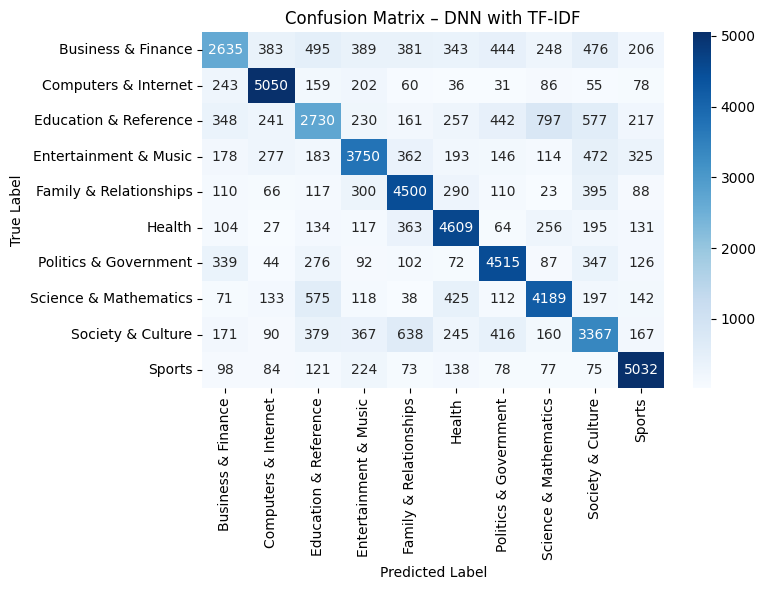

In [71]:
cm = confusion_matrix(y_test, y_test_pred_dnn)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix – DNN with TF-IDF")
plt.tight_layout()
plt.show()


In [110]:
# Classification report
print("DNN With TfIdf REPORT")
report = classification_report(y_test, y_test_pred_dnn,
                              target_names=label_encoder.classes_,
                              digits=4)
print(report)

DNN With TfIdf REPORT
                        precision    recall  f1-score   support

    Business & Finance     0.6132    0.4392    0.5118      6000
  Computers & Internet     0.7897    0.8417    0.8148      6000
 Education & Reference     0.5281    0.4550    0.4889      6000
 Entertainment & Music     0.6478    0.6250    0.6362      6000
Family & Relationships     0.6739    0.7501    0.7099      5999
                Health     0.6975    0.7682    0.7311      6000
 Politics & Government     0.7101    0.7525    0.7307      6000
 Science & Mathematics     0.6939    0.6982    0.6960      6000
     Society & Culture     0.5469    0.5612    0.5540      6000
                Sports     0.7727    0.8387    0.8043      6000

              accuracy                         0.6730     59999
             macro avg     0.6674    0.6730    0.6678     59999
          weighted avg     0.6674    0.6730    0.6678     59999



#Hyperparameter training for NNs


In [72]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU Available: {gpus}")
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print("No GPU found, using CPU")


GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [73]:
def hyperparameter_tuning(model_builder, X_train, y_train, X_val, y_val,
                         embedding_matrix, max_sequence_length, num_classes, model_name):

    best_model = None
    best_val_acc = 0
    best_params = {}
    best_history = None

    # Define parameter combinations to test
    param_combinations = [
        {'batch_size': 64, 'epochs': 25, 'learning_rate': 0.0005},
        {'batch_size': 128, 'epochs': 20, 'learning_rate': 0.001},
    ]


    for i, params in enumerate(param_combinations):
        model = model_builder(embedding_matrix, max_sequence_length, num_classes)
        callbacks = [
            EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
            ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)
        ]

        # Train model with GPU context
        with tf.device('/GPU:0' if gpus else '/CPU:0'):
            history = model.fit(
                X_train, y_train,
                batch_size=params['batch_size'],
                epochs=params['epochs'],
                validation_data=(X_val, y_val),
                callbacks=callbacks,
                verbose=1
            )

        # Evaluate on validation set
        val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
        print(f"  Validation Accuracy: {val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model = model
            best_params = params
            best_history = history

    return best_model, best_params, best_history

In [74]:
def train_and_evaluate_model(model_builder, X_train, y_train, X_val, y_val, X_test, y_test,
                           embedding_matrix, max_sequence_length, num_classes, model_name):

    # Hyperparameter tuning
    best_model, best_params, history = hyperparameter_tuning(
        model_builder, X_train, y_train, X_val, y_val,
        embedding_matrix=embedding_matrix,
        max_sequence_length=max_sequence_length,
        num_classes=num_classes,
        model_name=model_name
    )

    with tf.device('/GPU:0' if gpus else '/CPU:0'):
        test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose=0)
        y_test_pred_proba = best_model.predict(X_test, verbose=0)
        y_test_pred = np.argmax(y_test_pred_proba, axis=1)
        test_f1 = f1_score(y_test, y_test_pred, average='macro')

    print(f"  Test Accuracy: {test_acc:.4f}")
    print(f"  Test F1 Score (macro): {test_f1:.4f}")

    return {
        'model': model_name,
        'test_acc': test_acc,
        'test_f1': test_f1,
        'y_test_pred': y_test_pred,
    }

In [75]:
x_train_pad = x_train_pad.astype('int32')
x_test_pad = x_test_pad.astype('int32')
y_train = y_train.astype('int32')
y_test = y_test.astype('int32')


In [76]:
x_train_rnn, x_val_rnn, y_train_rnn, y_val_rnn = train_test_split(
        x_train_pad, y_train, test_size=0.3, random_state=42, stratify=y_train
    )

In [77]:
num_classes = len(np.unique(y_train))

#Simple RNN

In [78]:
def simple_rnn(embedding_matrix,max_sequence_length,num_classes):
    vocab_size,embedding_dim=embedding_matrix.shape
    with tf.device('/GPU:0' if gpus else '/CPU:0'):
        model=Sequential([
            Embedding(
            input_dim=vocab_size,output_dim=embedding_dim,weights=[embedding_matrix],input_length=max_sequence_length),
            SimpleRNN(128,return_sequences=True),
            Dropout(0.3),
            SimpleRNN(64,return_sequences=False),
            Dropout(0.3),
            Dense(32, activation='relu'),
            Dropout(0.2),
            Dense(num_classes, activation='softmax')
        ])
        model.compile(
            optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )
    return model

In [79]:
result = train_and_evaluate_model(
            simple_rnn, x_train_rnn, y_train_rnn, x_val_rnn, y_val_rnn,
            x_test_pad, y_test,
            embedding_matrix=embedding_matrix,
            max_sequence_length=max_sequence_length,
            num_classes=num_classes,
            model_name='SimpleRNN'
)
all_results.append(result)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 50s 43ms/step - accuracy: 0.0994 - loss: 2.3341 - val_accuracy: 0.1010 - val_loss: 2.3026 - learning_rate: 0.0010
Epoch 2/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 39s 38ms/step - accuracy: 0.1004 - loss: 2.3031 - val_accuracy: 0.1009 - val_loss: 2.3027 - learning_rate: 0.0010
Epoch 3/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 39s 38ms/step - accuracy: 0.1028 - loss: 2.3085 - val_accuracy: 0.1273 - val_loss: 2.2859 - learning_rate: 0.0010
Epoch 4/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 39s 38ms/step - accuracy: 0.1239 - loss: 2.2892 - val_accuracy: 0.1112 - val_loss: 2.2960 - learning_rate: 0.0010
Epoch 5/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 39s 38ms/step - accuracy: 0.1015 - loss: 2.3032 - val_accuracy: 0.1021 - val_loss: 2.3022 - learning_rate: 0.0010
Epoch 6/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 39s 38ms/step - accuracy: 0.0998 - loss: 2.3022 - val_accuracy: 0.1009 - val_loss: 2.3027 - learning_rate: 0.0010
Epoch 7/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 39s 38ms/step - accura

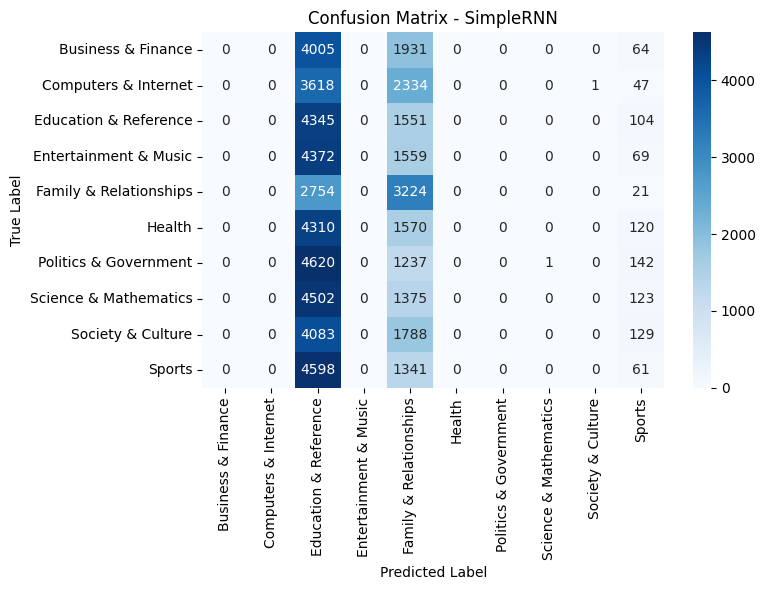

In [111]:
cm = confusion_matrix(y_test, all_results[1]['y_test_pred'])
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - SimpleRNN")
plt.tight_layout()
plt.show()

In [112]:
print("Classification Report - SimpleRNN")
report = classification_report(y_test, all_results[1]['y_test_pred'],
                              target_names=label_encoder.classes_,
                              digits=4)
print(report)
keras.backend.clear_session()

Classification Report - SimpleRNN
                        precision    recall  f1-score   support

    Business & Finance     0.0000    0.0000    0.0000      6000
  Computers & Internet     0.0000    0.0000    0.0000      6000
 Education & Reference     0.1054    0.7242    0.1841      6000
 Entertainment & Music     0.0000    0.0000    0.0000      6000
Family & Relationships     0.1800    0.5374    0.2697      5999
                Health     0.0000    0.0000    0.0000      6000
 Politics & Government     0.0000    0.0000    0.0000      6000
 Science & Mathematics     0.0000    0.0000    0.0000      6000
     Society & Culture     0.0000    0.0000    0.0000      6000
                Sports     0.0693    0.0102    0.0177      6000

              accuracy                         0.1272     59999
             macro avg     0.0355    0.1272    0.0472     59999
          weighted avg     0.0355    0.1272    0.0471     59999



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


#Bidirectional SimpleRNN

In [82]:
def bi_rnn(embedding_matrix,max_sequence_length,num_classes):
    vocab_size,embedding_dim=embedding_matrix.shape
    with tf.device('/GPU:0' if gpus else '/CPU:0'):
        model=Sequential([
            Embedding(
            input_dim=vocab_size,output_dim=embedding_dim,weights=[embedding_matrix],input_length=max_sequence_length),
            Bidirectional(SimpleRNN(128,return_sequences=True)),
            Dropout(0.3),
            Bidirectional(SimpleRNN(64,return_sequences=False)),
            Dropout(0.3),
            Dense(32, activation='relu'),
            Dropout(0.2),
            Dense(num_classes, activation='softmax')
        ])
        model.compile(
            optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )
    return model

In [83]:
result = train_and_evaluate_model(
            bi_rnn, x_train_rnn, y_train_rnn, x_val_rnn, y_val_rnn,
            x_test_pad, y_test,
            embedding_matrix=embedding_matrix,
            max_sequence_length=max_sequence_length,
            num_classes=num_classes,
            model_name='Bidirectional SimpleRNN'
)
all_results.append(result)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 88s 77ms/step - accuracy: 0.2598 - loss: 2.0387 - val_accuracy: 0.5490 - val_loss: 1.3686 - learning_rate: 0.0010
Epoch 2/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 73s 72ms/step - accuracy: 0.5560 - loss: 1.4147 - val_accuracy: 0.6131 - val_loss: 1.2258 - learning_rate: 0.0010
Epoch 3/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 73s 72ms/step - accuracy: 0.6097 - loss: 1.2700 - val_accuracy: 0.6121 - val_loss: 1.2659 - learning_rate: 0.0010
Epoch 4/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 82s 72ms/step - accuracy: 0.6349 - loss: 1.2093 - val_accuracy: 0.6288 - val_loss: 1.2053 - learning_rate: 0.0010
Epoch 5/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 73s 72ms/step - accuracy: 0.6477 - loss: 1.1801 - val_accuracy: 0.6410 - val_loss: 1.2033 - learning_rate: 0.0010
Epoch 6/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 73s 72ms/step - accuracy: 0.6661 - loss: 1.1305 - val_accuracy: 0.6474 - val_loss: 1.1738 - learning_rate: 0.0010
Epoch 7/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 73s 72ms/step - accura

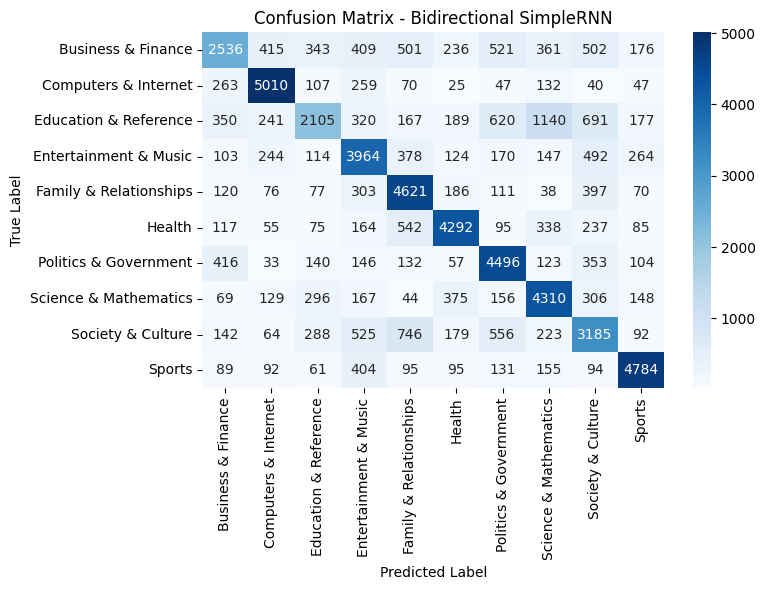

In [113]:
cm = confusion_matrix(y_test, all_results[2]['y_test_pred'])
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Bidirectional SimpleRNN")
plt.tight_layout()
plt.show()

In [114]:
print("Classification Report - Birectional SimpleRNN")
report = classification_report(y_test, all_results[2]['y_test_pred'],
                              target_names=label_encoder.classes_,
                              digits=4)
print(report)
keras.backend.clear_session()

Classification Report - Birectional SimpleRNN
                        precision    recall  f1-score   support

    Business & Finance     0.6031    0.4227    0.4970      6000
  Computers & Internet     0.7879    0.8350    0.8107      6000
 Education & Reference     0.5837    0.3508    0.4383      6000
 Entertainment & Music     0.5951    0.6607    0.6262      6000
Family & Relationships     0.6334    0.7703    0.6951      5999
                Health     0.7454    0.7153    0.7301      6000
 Politics & Government     0.6513    0.7493    0.6969      6000
 Science & Mathematics     0.6186    0.7183    0.6648      6000
     Society & Culture     0.5058    0.5308    0.5180      6000
                Sports     0.8044    0.7973    0.8009      6000

              accuracy                         0.6551     59999
             macro avg     0.6529    0.6551    0.6478     59999
          weighted avg     0.6529    0.6551    0.6478     59999



#GRU

In [86]:
def gru(embedding_matrix,max_sequence_length,num_classes):
    vocab_size,embedding_dim=embedding_matrix.shape
    with tf.device('/GPU:0' if gpus else '/CPU:0'):
        model=Sequential([
            Embedding(
            input_dim=vocab_size,output_dim=embedding_dim,weights=[embedding_matrix],input_length=max_sequence_length),
            GRU(128,return_sequences=True),
            Dropout(0.3),
            GRU(64,return_sequences=False),
            Dropout(0.3),
            Dense(32, activation='relu'),
            Dropout(0.2),
            Dense(num_classes, activation='softmax')
        ])
        model.compile(
            optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )
    return model

In [87]:
result = train_and_evaluate_model(
            gru, x_train_rnn, y_train_rnn, x_val_rnn, y_val_rnn,
            x_test_pad, y_test,
            embedding_matrix=embedding_matrix,
            max_sequence_length=max_sequence_length,
            num_classes=num_classes,
            model_name='GRU'
)
all_results.append(result)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 38s 31ms/step - accuracy: 0.1004 - loss: 2.3027 - val_accuracy: 0.1073 - val_loss: 2.2904 - learning_rate: 0.0010
Epoch 2/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 32s 31ms/step - accuracy: 0.1568 - loss: 2.1985 - val_accuracy: 0.6674 - val_loss: 1.0495 - learning_rate: 0.0010
Epoch 3/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 31s 31ms/step - accuracy: 0.6613 - loss: 1.1052 - val_accuracy: 0.6848 - val_loss: 1.0020 - learning_rate: 0.0010
Epoch 4/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 32s 31ms/step - accuracy: 0.7006 - loss: 0.9859 - val_accuracy: 0.6861 - val_loss: 1.0062 - learning_rate: 0.0010
Epoch 5/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 31s 31ms/step - accuracy: 0.7197 - loss: 0.9197 - val_accuracy: 0.6915 - val_loss: 1.0127 - learning_rate: 0.0010
Epoch 6/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 32s 31ms/step - accuracy: 0.7383 - loss: 0.8607 - val_accuracy: 0.6881 - val_loss: 1.0586 - learning_rate: 0.0010
Epoch 7/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 32s 31ms/step - accura

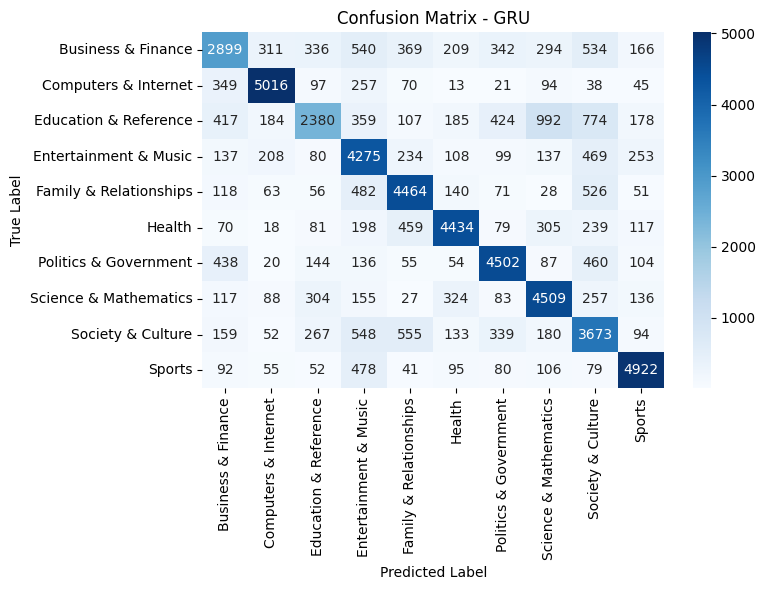

In [115]:
cm = confusion_matrix(y_test, all_results[3]['y_test_pred'])
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - GRU")
plt.tight_layout()
plt.show()

In [116]:
print("Classification Report - GRU")
report = classification_report(y_test, all_results[3]['y_test_pred'],
                              target_names=label_encoder.classes_,
                              digits=4)
print(report)
keras.backend.clear_session()

Classification Report - GRU
                        precision    recall  f1-score   support

    Business & Finance     0.6045    0.4832    0.5371      6000
  Computers & Internet     0.8339    0.8360    0.8350      6000
 Education & Reference     0.6268    0.3967    0.4859      6000
 Entertainment & Music     0.5755    0.7125    0.6367      6000
Family & Relationships     0.6996    0.7441    0.7212      5999
                Health     0.7786    0.7390    0.7583      6000
 Politics & Government     0.7454    0.7503    0.7478      6000
 Science & Mathematics     0.6698    0.7515    0.7083      6000
     Society & Culture     0.5211    0.6122    0.5630      6000
                Sports     0.8114    0.8203    0.8158      6000

              accuracy                         0.6846     59999
             macro avg     0.6866    0.6846    0.6809     59999
          weighted avg     0.6866    0.6846    0.6809     59999



#Bidirectional GRU

In [90]:
def bi_gru(embedding_matrix,max_sequence_length,num_classes):
    vocab_size,embedding_dim=embedding_matrix.shape
    with tf.device('/GPU:0' if gpus else '/CPU:0'):
        model=Sequential([
            Embedding(
            input_dim=vocab_size,output_dim=embedding_dim,weights=[embedding_matrix],input_length=max_sequence_length),
            Bidirectional(GRU(128,return_sequences=True)),
            Dropout(0.3),
            Bidirectional(GRU(64,return_sequences=False)),
            Dropout(0.3),
            Dense(32, activation='relu'),
            Dropout(0.2),
            Dense(num_classes, activation='softmax')
        ])
        model.compile(
            optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )
    return model

In [91]:
result = train_and_evaluate_model(
            bi_gru, x_train_rnn, y_train_rnn, x_val_rnn, y_val_rnn,
            x_test_pad, y_test,
            embedding_matrix=embedding_matrix,
            max_sequence_length=max_sequence_length,
            num_classes=num_classes,
            model_name='Bidirectional GRU'
)
all_results.append(result)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 57s 52ms/step - accuracy: 0.4806 - loss: 1.5455 - val_accuracy: 0.6757 - val_loss: 1.0110 - learning_rate: 0.0010
Epoch 2/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 52s 51ms/step - accuracy: 0.6847 - loss: 1.0288 - val_accuracy: 0.6912 - val_loss: 0.9693 - learning_rate: 0.0010
Epoch 3/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 56s 54ms/step - accuracy: 0.7099 - loss: 0.9498 - val_accuracy: 0.6930 - val_loss: 0.9677 - learning_rate: 0.0010
Epoch 4/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 52s 51ms/step - accuracy: 0.7256 - loss: 0.8957 - val_accuracy: 0.6936 - val_loss: 0.9808 - learning_rate: 0.0010
Epoch 5/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 52s 51ms/step - accuracy: 0.7417 - loss: 0.8399 - val_accuracy: 0.6872 - val_loss: 1.0081 - learning_rate: 0.0010
Epoch 6/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 52s 51ms/step - accuracy: 0.7583 - loss: 0.7904 - val_accuracy: 0.6832 - val_loss: 1.0646 - learning_rate: 0.0010
Epoch 7/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 52s 51ms/step - accura

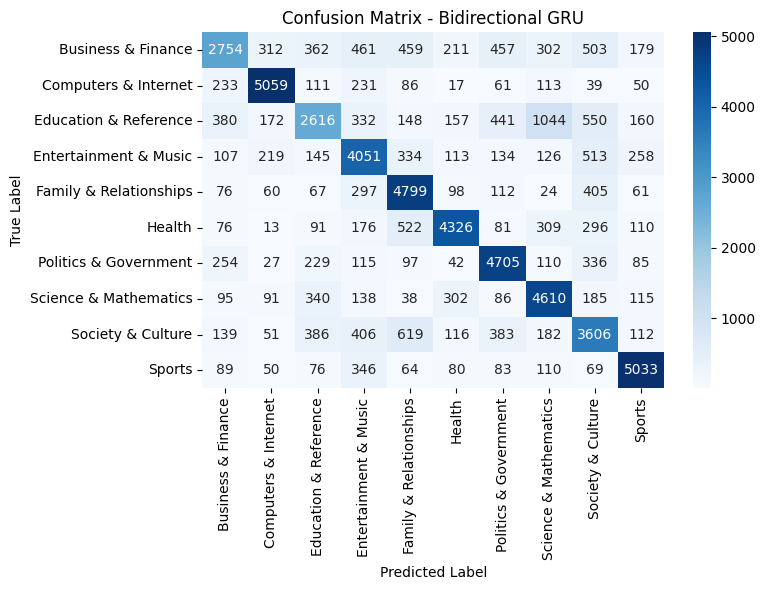

In [117]:
cm = confusion_matrix(y_test, all_results[4]['y_test_pred'])
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Bidirectional GRU")
plt.tight_layout()
plt.show()


In [118]:
print("Classification Report - Bidirectional GRU")
report = classification_report(y_test, all_results[4]['y_test_pred'],
                              target_names=label_encoder.classes_,
                              digits=4)
print(report)
keras.backend.clear_session()

Classification Report - Bidirectional GRU
                        precision    recall  f1-score   support

    Business & Finance     0.6552    0.4590    0.5398      6000
  Computers & Internet     0.8356    0.8432    0.8394      6000
 Education & Reference     0.5915    0.4360    0.5020      6000
 Entertainment & Music     0.6182    0.6752    0.6454      6000
Family & Relationships     0.6697    0.8000    0.7291      5999
                Health     0.7920    0.7210    0.7548      6000
 Politics & Government     0.7191    0.7842    0.7502      6000
 Science & Mathematics     0.6652    0.7683    0.7131      6000
     Society & Culture     0.5546    0.6010    0.5769      6000
                Sports     0.8166    0.8388    0.8276      6000

              accuracy                         0.6927     59999
             macro avg     0.6918    0.6927    0.6878     59999
          weighted avg     0.6918    0.6927    0.6878     59999



#LSTM

In [94]:
def lstm(embedding_matrix,max_sequence_length,num_classes):
    vocab_size,embedding_dim=embedding_matrix.shape
    with tf.device('/GPU:0' if gpus else '/CPU:0'):
        model=Sequential([
            Embedding(
            input_dim=vocab_size,output_dim=embedding_dim,weights=[embedding_matrix],input_length=max_sequence_length),
            LSTM(128,return_sequences=True),
            Dropout(0.3),
            LSTM(64,return_sequences=False),
            Dropout(0.3),
            Dense(32, activation='relu'),
            Dropout(0.2),
            Dense(num_classes, activation='softmax')
        ])
        model.compile(
            optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )
    return model

In [95]:
result = train_and_evaluate_model(
            lstm, x_train_rnn, y_train_rnn, x_val_rnn, y_val_rnn,
            x_test_pad, y_test,
            embedding_matrix=embedding_matrix,
            max_sequence_length=max_sequence_length,
            num_classes=num_classes,
            model_name='LSTM'
)
all_results.append(result)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 37s 33ms/step - accuracy: 0.1020 - loss: 2.3012 - val_accuracy: 0.1341 - val_loss: 2.2679 - learning_rate: 0.0010
Epoch 2/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 33s 32ms/step - accuracy: 0.1228 - loss: 2.2755 - val_accuracy: 0.1336 - val_loss: 2.2805 - learning_rate: 0.0010
Epoch 3/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 41s 33ms/step - accuracy: 0.3243 - loss: 1.9137 - val_accuracy: 0.6057 - val_loss: 1.2183 - learning_rate: 0.0010
Epoch 4/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 33s 32ms/step - accuracy: 0.6129 - loss: 1.2538 - val_accuracy: 0.6681 - val_loss: 1.0867 - learning_rate: 0.0010
Epoch 5/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 34s 34ms/step - accuracy: 0.6736 - loss: 1.0996 - val_accuracy: 0.6780 - val_loss: 1.0540 - learning_rate: 0.0010
Epoch 6/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 33s 32ms/step - accuracy: 0.6997 - loss: 1.0209 - val_accuracy: 0.6819 - val_loss: 1.0652 - learning_rate: 0.0010
Epoch 7/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 33s 33ms/step - accura

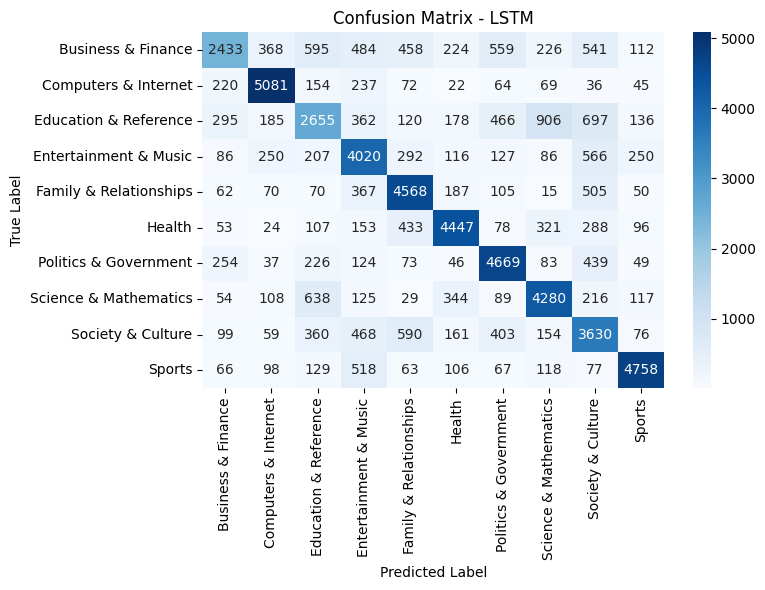

In [119]:

cm = confusion_matrix(y_test, all_results[5]['y_test_pred'])
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - LSTM")
plt.tight_layout()
plt.show()

In [120]:
print("\nClassification Report - LSTM")
report = classification_report(y_test, all_results[5]['y_test_pred'],
                              target_names=label_encoder.classes_,
                              digits=4)
print(report)
keras.backend.clear_session()


Classification Report - LSTM
                        precision    recall  f1-score   support

    Business & Finance     0.6717    0.4055    0.5057      6000
  Computers & Internet     0.8091    0.8468    0.8275      6000
 Education & Reference     0.5164    0.4425    0.4766      6000
 Entertainment & Music     0.5862    0.6700    0.6253      6000
Family & Relationships     0.6820    0.7615    0.7195      5999
                Health     0.7626    0.7412    0.7518      6000
 Politics & Government     0.7045    0.7782    0.7395      6000
 Science & Mathematics     0.6839    0.7133    0.6983      6000
     Society & Culture     0.5189    0.6050    0.5587      6000
                Sports     0.8364    0.7930    0.8141      6000

              accuracy                         0.6757     59999
             macro avg     0.6772    0.6757    0.6717     59999
          weighted avg     0.6772    0.6757    0.6717     59999



#Bidirectional LSTM

In [98]:
def bi_lstm(embedding_matrix,max_sequence_length,num_classes):
    vocab_size,embedding_dim=embedding_matrix.shape
    with tf.device('/GPU:0' if gpus else '/CPU:0'):
        model=Sequential([
            Embedding(
            input_dim=vocab_size,output_dim=embedding_dim,weights=[embedding_matrix],input_length=max_sequence_length),
            Bidirectional(LSTM(128,return_sequences=True)),
            Dropout(0.3),
            Bidirectional(LSTM(64,return_sequences=False)),
            Dropout(0.3),
            Dense(32, activation='relu'),
            Dropout(0.2),
            Dense(num_classes, activation='softmax')
        ])
        model.compile(
            optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )
    return model

In [99]:
result = train_and_evaluate_model(
            bi_lstm, x_train_rnn, y_train_rnn, x_val_rnn, y_val_rnn,
            x_test_pad, y_test,
            embedding_matrix=embedding_matrix,
            max_sequence_length=max_sequence_length,
            num_classes=num_classes,
            model_name='Bidirectional LSTM'
)
all_results.append(result)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 60s 55ms/step - accuracy: 0.5000 - loss: 1.5186 - val_accuracy: 0.6666 - val_loss: 1.0555 - learning_rate: 0.0010
Epoch 2/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 55s 54ms/step - accuracy: 0.6803 - loss: 1.0464 - val_accuracy: 0.6850 - val_loss: 0.9991 - learning_rate: 0.0010
Epoch 3/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 55s 54ms/step - accuracy: 0.7075 - loss: 0.9626 - val_accuracy: 0.6880 - val_loss: 1.0035 - learning_rate: 0.0010
Epoch 4/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 86s 57ms/step - accuracy: 0.7268 - loss: 0.9045 - val_accuracy: 0.6875 - val_loss: 1.0081 - learning_rate: 0.0010
Epoch 5/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 55s 54ms/step - accuracy: 0.7411 - loss: 0.8516 - val_accuracy: 0.6838 - val_loss: 1.0357 - learning_rate: 0.0010
Epoch 6/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 55s 54ms/step - accuracy: 0.7585 - loss: 0.7934 - val_accuracy: 0.6888 - val_loss: 1.0466 - learning_rate: 5.0000e-04
Epoch 7/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 55s 54ms/step - ac

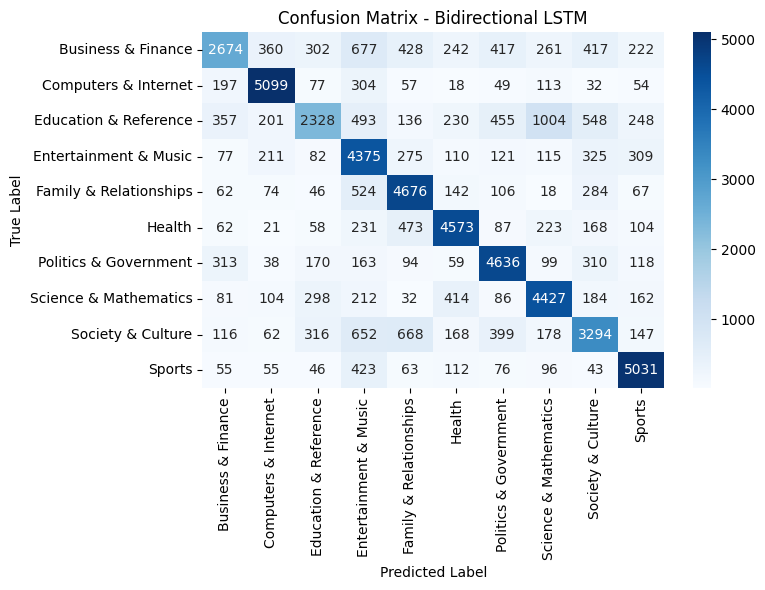

In [121]:
cm = confusion_matrix(y_test, all_results[6]['y_test_pred'])
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Bidirectional LSTM")
plt.tight_layout()
plt.show()

In [122]:
print("Classification Report - Bidirectional LSTM")
report = classification_report(y_test, all_results[6]['y_test_pred'],
                              target_names=label_encoder.classes_,
                              digits=4)
print(report)
keras.backend.clear_session()

Classification Report - Bidirectional LSTM
                        precision    recall  f1-score   support

    Business & Finance     0.6695    0.4457    0.5351      6000
  Computers & Internet     0.8191    0.8498    0.8342      6000
 Education & Reference     0.6253    0.3880    0.4789      6000
 Entertainment & Music     0.5432    0.7292    0.6226      6000
Family & Relationships     0.6775    0.7795    0.7249      5999
                Health     0.7536    0.7622    0.7579      6000
 Politics & Government     0.7208    0.7727    0.7458      6000
 Science & Mathematics     0.6775    0.7378    0.7064      6000
     Society & Culture     0.5877    0.5490    0.5677      6000
                Sports     0.7786    0.8385    0.8074      6000

              accuracy                         0.6852     59999
             macro avg     0.6853    0.6852    0.6781     59999
          weighted avg     0.6853    0.6852    0.6781     59999



# DNN with Skipgram

In [102]:
def skipgram_dnn(embedding_matrix, max_sequence_length, num_classes):
    """
    DNN model using Skip-gram embeddings
    """
    vocab_size, embedding_dim = embedding_matrix.shape

    with tf.device('/GPU:0' if gpus else '/CPU:0'):
        model = Sequential([
            # Embedding layer with Skip-gram embeddings
            Embedding(
                input_dim=vocab_size,
                output_dim=embedding_dim,
                weights=[embedding_matrix],
                input_length=max_sequence_length,
                trainable=True
            ),
            Flatten(),

            Dense(512, activation='relu'),
            Dropout(0.5),
            BatchNormalization(),

            Dense(256, activation='relu'),
            Dropout(0.4),
            BatchNormalization(),

            Dense(128, activation='relu'),
            Dropout(0.3),

            Dense(64, activation='relu'),
            Dropout(0.2),

            Dense(num_classes, activation='softmax')
        ])


        model.compile(
            optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )

    return model


In [103]:
skipgram_dnn_result = train_and_evaluate_model(
    skipgram_dnn,
    x_train_rnn, y_train_rnn, x_val_rnn, y_val_rnn,
    x_test_pad, y_test,
    embedding_matrix=embedding_matrix,
    max_sequence_length=max_sequence_length,
    num_classes=num_classes,
    model_name='SkipGram_DNN'
)
all_results.append(skipgram_dnn_result)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - accuracy: 0.2200 - loss: 2.1752 - val_accuracy: 0.5901 - val_loss: 1.2354 - learning_rate: 0.0010
Epoch 2/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.5518 - loss: 1.3596 - val_accuracy: 0.6143 - val_loss: 1.1926 - learning_rate: 0.0010
Epoch 3/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.6281 - loss: 1.1694 - val_accuracy: 0.6512 - val_loss: 1.0965 - learning_rate: 0.0010
Epoch 4/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.6714 - loss: 1.0405 - val_accuracy: 0.6547 - val_loss: 1.0929 - learning_rate: 0.0010
Epoch 5/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.7055 - loss: 0.9411 - val_accuracy: 0.6541 - val_loss: 1.1235 - learning_rate: 0.0010
Epoch 6/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.7297 - loss: 0.8630 - val_accuracy: 0.6498 - val_loss: 1.1777 - learning_rate: 0.0010
Epoch 7/25
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.

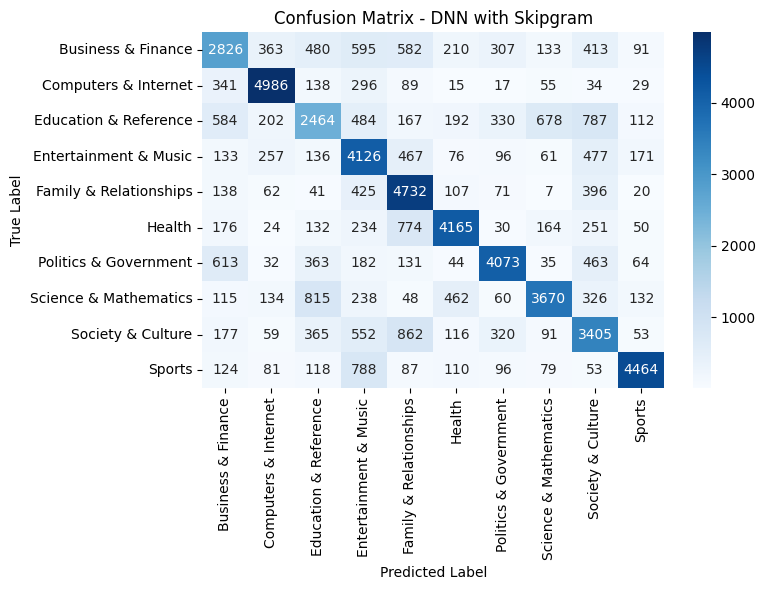

In [123]:
cm = confusion_matrix(y_test, all_results[7]['y_test_pred'])
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - DNN with Skipgram")
plt.tight_layout()
plt.show()

In [124]:
print("Classification Report - DNN with skipgram")
report = classification_report(y_test, all_results[7]['y_test_pred'],
                              target_names=label_encoder.classes_,
                              digits=4)
print(report)
keras.backend.clear_session()

Classification Report - DNN with skipgram
                        precision    recall  f1-score   support

    Business & Finance     0.5407    0.4710    0.5034      6000
  Computers & Internet     0.8042    0.8310    0.8174      6000
 Education & Reference     0.4877    0.4107    0.4459      6000
 Entertainment & Music     0.5210    0.6877    0.5928      6000
Family & Relationships     0.5960    0.7888    0.6790      5999
                Health     0.7577    0.6942    0.7245      6000
 Politics & Government     0.7543    0.6788    0.7146      6000
 Science & Mathematics     0.7380    0.6117    0.6689      6000
     Society & Culture     0.5155    0.5675    0.5403      6000
                Sports     0.8608    0.7440    0.7981      6000

              accuracy                         0.6485     59999
             macro avg     0.6576    0.6485    0.6485     59999
          weighted avg     0.6576    0.6485    0.6485     59999



# Random Forest

In [106]:
def train_ml_model(model, x_train, y_train, x_val, y_val, x_test, y_test, model_name):
    # Train the model
    print(f"Training {model_name}...")
    model.fit(x_train, y_train)

    # Make predictions
    y_test_pred = model.predict(x_test)

    # Calculate metrics
    test_acc = accuracy_score(y_test, y_test_pred)
    test_f1 = f1_score(y_test, y_test_pred, average='macro')

    # Print results
    print(f"{model_name} Performance:")
    print(f"  Test Accuracy:       {test_acc:.4f}")
    print(f"  Test F1:             {test_f1:.4f}")

    # Return model and metrics
    return {
        'Model': model,
        'Accuracy': test_acc,
        'F1_score': test_f1,
        'y_test_pred': y_test_pred
    }

def hyperparameter_tuning_random_forest(x_train,y_train,x_val,y_val):
    best_model=None
    best_val_acc=0
    best_params={}
    validation_accuracies=[]
    param_combinations=[
        {'n_estimators': 200, 'max_depth': 15, 'min_samples_split': 2, 'min_samples_leaf': 1},
        {'n_estimators': 200, 'max_depth': None, 'min_samples_split': 10, 'min_samples_leaf': 4},
        {'n_estimators': 100, 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 1, 'class_weight': 'balanced'},
    ]
    for i, params in enumerate(param_combinations):
        # Initialize Random Forest with current parameters
        rf_model = RandomForestClassifier(
            n_estimators=params['n_estimators'],
            max_depth=params['max_depth'],
            min_samples_split=params['min_samples_split'],
            min_samples_leaf=params.get('min_samples_leaf', 1),
            class_weight=params.get('class_weight', None),
            random_state=42,
            verbose=0
        )
        rf_model.fit(x_train, y_train)
        y_val_pred=rf_model.predict(x_val)
        val_acc = accuracy_score(y_val, y_val_pred)
        validation_accuracies.append(val_acc)
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model = rf_model
            best_params = params
    print("RANDOM FOREST HYPERPARAMETER TUNING RESULTS")
    print(f"{'='*50}")
    print(f"Best Parameters: {best_params}")
    print(f"Best Validation Accuracy: {best_val_acc:.4f}")
    print(f"Number of trees in best model: {best_params['n_estimators']}")
    print(f"Maximum depth: {best_params['max_depth']}")
    print(f"Minimum samples split: {best_params['min_samples_split']}")
    print(f"{'='*50}")
    return best_model, best_params

x_train_ml,x_val_ml,y_train_ml,y_val_ml=train_test_split(
    x_train_tfidf,y_train,test_size=0.25,random_state=42,stratify=y_train
)
best_rf_model,best_rf_params=hyperparameter_tuning_random_forest(x_train_ml,y_train_ml,x_val_ml,y_val_ml)
rf_results=train_ml_model(best_rf_model,x_train_ml,y_train_ml,x_val_ml,y_val_ml,x_test_tfidf,y_test,"Random Forest")

RANDOM FOREST HYPERPARAMETER TUNING RESULTS
Best Parameters: {'n_estimators': 200, 'max_depth': None, 'min_samples_split': 10, 'min_samples_leaf': 4}
Best Validation Accuracy: 0.6110
Number of trees in best model: 200
Maximum depth: None
Minimum samples split: 10
Training Random Forest...
Random Forest Performance:
  Test Accuracy:       0.6072
  Test F1:             0.6003


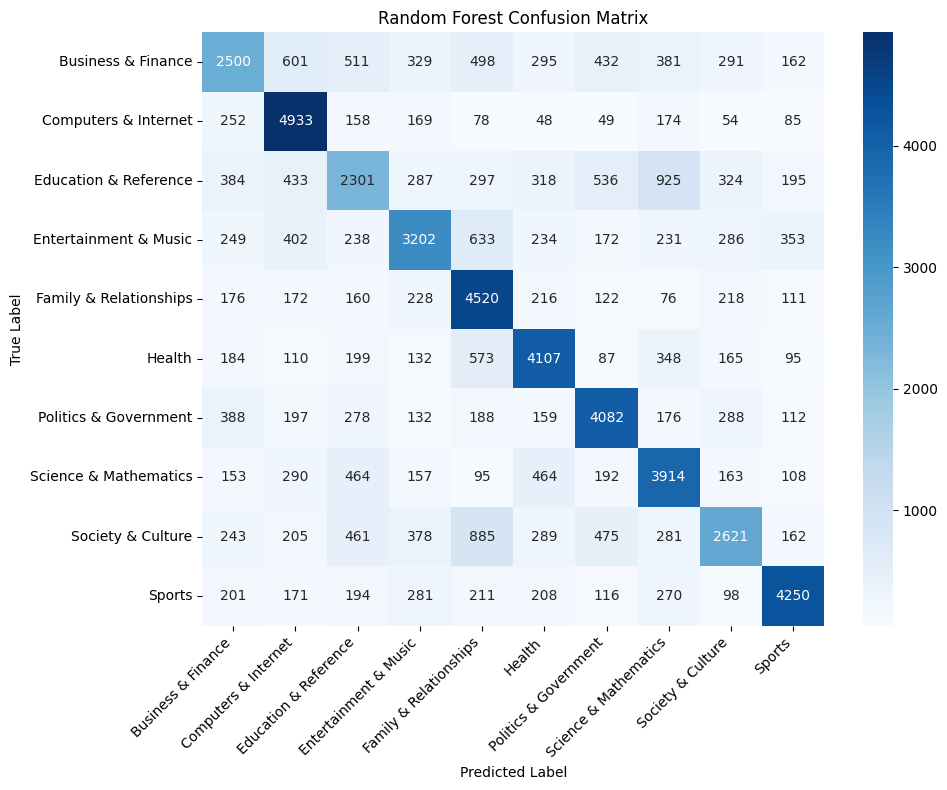

In [107]:
y_test_pred_rf = rf_results['y_test_pred']
cm_rf = confusion_matrix(y_test, y_test_pred_rf)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.title('Random Forest Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()




In [108]:
# Classification report
print("RANDOM FOREST CLASSIFICATION REPORT")
report = classification_report(y_test, y_test_pred_rf,
                              target_names=label_encoder.classes_,
                              digits=4)
print(report)

# Store Random Forest results
all_results.append(rf_results)

RANDOM FOREST CLASSIFICATION REPORT
                        precision    recall  f1-score   support

    Business & Finance     0.5285    0.4167    0.4660      6000
  Computers & Internet     0.6565    0.8222    0.7301      6000
 Education & Reference     0.4635    0.3835    0.4197      6000
 Entertainment & Music     0.6047    0.5337    0.5670      6000
Family & Relationships     0.5666    0.7535    0.6468      5999
                Health     0.6480    0.6845    0.6657      6000
 Politics & Government     0.6518    0.6803    0.6657      6000
 Science & Mathematics     0.5776    0.6523    0.6127      6000
     Society & Culture     0.5814    0.4368    0.4989      6000
                Sports     0.7545    0.7083    0.7307      6000

              accuracy                         0.6072     59999
             macro avg     0.6033    0.6072    0.6003     59999
          weighted avg     0.6033    0.6072    0.6003     59999

